# 机器学习应用建议

本实验将探索用于评估和改进机器学习模型的技术

## 导入库

In [3]:
import numpy as np

import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense
from keras.activations import relu, linear
from keras.losses import SparseCategoricalCrossentropy
from keras.optimizers import Adam

import logging

logging.getLogger('tensorflow').setLevel(logging.ERROR)

tf.keras.backend.set_floatx('float64')

from utils import *

tf.autograph.set_verbosity(0)

d:\coding\machine_learning\lab05_advice_for_applying_machine_learning\utils.py:150: SyntaxWarning: invalid escape sequence '\l'
  ax[0].plot(x, y_pred[:, i], lw=0.5, label=f'$\lambda =${lambda_range[i]}')


## 评估学习算法(多项式回归)

假设我们现在构建了一个机器学习模型，发现它能很好地拟合训练数据，现在我们要测试它的表现
* 将原始数据划分成训练集和测试集
* 构建误差函数来评估模型 

In [5]:
# 划分数据集
# 生成一些数据
X,y,x_ideal,y_ideal = gen_data(18, 2, 0.7)
print("X.shape", X.shape, "y.shape", y.shape)

# 使用 sklearn 函数划分数据 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.33, random_state=1)
print("X_train.shape", X_train.shape, "y_train.shape", y_train.shape)
print("X_test.shape", X_test.shape, "y_test.shape", y_test.shape)

X.shape (18,) y.shape (18,)
X_train.shape (12,) y_train.shape (12,)
X_test.shape (6,) y_test.shape (6,)


绘制训练集和测试集
下图中，用于训练的数据点（红色）与模型未用来训练的数据点（测试集）交错分布。这个数据集由添加了噪声的二次函数生成。图中同时给出了“理想”曲线供参考。

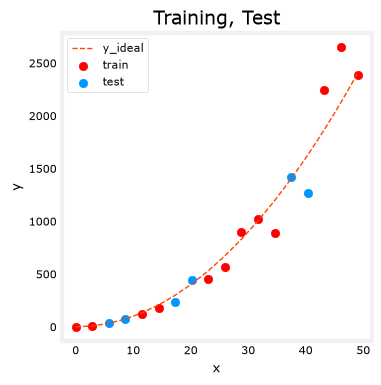

In [6]:
fig, ax = plt.subplots(1,1,figsize=(4,4))
ax.plot(x_ideal, y_ideal, "--", color = "orangered", label="y_ideal", lw=1)
ax.set_title("Training, Test",fontsize = 14)
ax.set_xlabel("x")
ax.set_ylabel("y")

ax.scatter(X_train, y_train, color = "red",           label="train")
ax.scatter(X_test, y_test,   color = dlc["dlblue"],   label="test")
ax.legend(loc='upper left')
plt.show()

使用均方误差（MSE）作为误差函数

In [ ]:
def eval_mse(y, yhat):
    """
    计算数据集上的均方误差。

    参数：
        y (ndarray Shape (m,) or (m,1)): 每个样本的目标值
        yhat (ndarray Shape (m,) or (m,1)): 每个样本的预测值

    返回：
        err (scalar): 误差
    """

    m = len(y)
    err = 0.0

    for i in range(m):
        err += (y[i] - yhat[i]) ** 2

    err /= (2 * m)

    return err

比较模型在训练数据和测试数据上的表现。

下面构建一个高次多项式模型，以最小化训练误差。这里将使用 `sklearn` 中的 linear_regression 相关函数。步骤如下：

- 创建并拟合模型（“拟合”也称为训练或运行梯度下降）。
- 计算训练数据上的误差。
- 计算测试数据上的误差。

In [ ]:
# 在 sklearn 中创建模型，并使用训练数据进行训练
degree = 10 # 先使用 10 次多项式
lmodel = lin_model(degree)
lmodel.fit(X_train, y_train)

# 预测训练数据并计算训练误差
yhat = lmodel.predict(X_train)
err_train = lmodel.mse(y_train, yhat)

# 预测测试数据并计算测试误差
yhat = lmodel.predict(X_test)
err_test = lmodel.mse(y_test, yhat)

print(f'training err = {err_train:0.2f} , test err = {err_test:0.2f}')

training err = 2086.18 , test err = 21384.05


验证误差远大于训练误差 -> 过拟合，高方差，泛化能力差

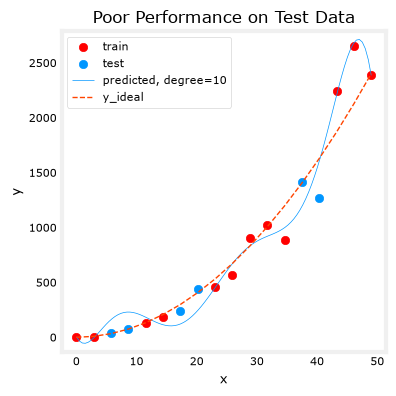

In [9]:
# 绘制数据范围内的预测结果
x = np.linspace(0, int(X.max()), 100)
y_pred = lmodel.predict(x).reshape(-1, 1)
plt_train_test(X_train, y_train, X_test, y_test, x, y_pred, x_ideal, y_ideal, degree)

下表给出了训练集、交叉验证集和测试集的一种典型划分比例，但具体比例可以根据可用数据量调整。

| 数据集           | 占总量的百分比 | 说明 |
|:-----------------|:----------:|:------------|
| 训练集           | 60         | 用于在训练或拟合过程中调整模型参数 $w$ 和 $b$ 的数据 |
| 交叉验证集       | 20         | 用于调整其他模型参数的数据，例如多项式次数、正则化强度或神经网络结构 |
| 测试集           | 20         | 用于在调优完成后测试模型，以衡量其在新数据上的表现 |

下面生成三个数据集。我们将再次使用 `sklearn` 中的 `train_test_split`，但会调用两次，以得到三个子集。

In [10]:
# 生成数据
X, y, x_ideal, y_ideal = gen_data(40, 5, 0.7)
print('X.shape', X.shape, 'y.shape', y.shape)

# 使用 sklearn 函数划分数据
X_train, X_, y_train, y_ = train_test_split(X, y, test_size=0.40, random_state=1)
X_cv, X_test, y_cv, y_test = train_test_split(X_, y_, test_size=0.50, random_state=1)
print('X_train.shape', X_train.shape, 'y_train.shape', y_train.shape)
print('X_cv.shape', X_cv.shape, 'y_cv.shape', y_cv.shape)
print('X_test.shape', X_test.shape, 'y_test.shape', y_test.shape)

X.shape (40,) y.shape (40,)
X_train.shape (24,) y_train.shape (24,)
X_cv.shape (8,) y_cv.shape (8,)
X_test.shape (8,) y_test.shape (8,)


## 偏差与方差

偏差和方差是机器学习模型性能的两个重要概念。偏差和方差是衡量模型泛化能力的重要指标。偏差和方差是衡量模型泛化能力的重要指标。

如何选择合适的模型，以在偏差和方差之间取得平衡？使用交叉验证集来选择模型参数，以最小化交叉验证误差。

### 使用交叉验证集选择模型参数

首先绘制训练集，交叉验证集和测试集

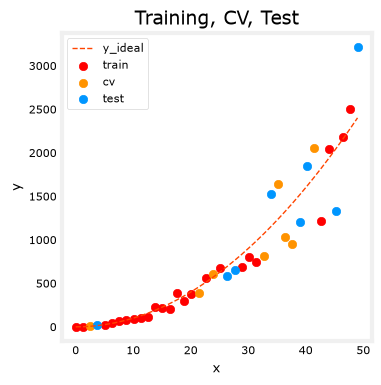

In [11]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.plot(x_ideal, y_ideal, '--', color='orangered', label='y_ideal', lw=1)
ax.set_title('Training, CV, Test', fontsize=14)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.scatter(X_train, y_train, color='red', label='train')
ax.scatter(X_cv, y_cv, color=dlc['dlorange'], label='cv')
ax.scatter(X_test, y_test, color=dlc['dlblue'], label='test')
ax.legend(loc='upper left')
plt.show()

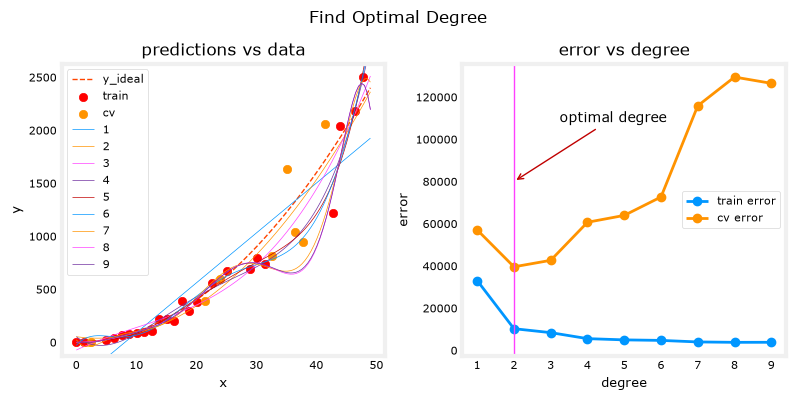

In [ ]:
# 寻找最优多项式次数
max_degree = 9
err_train = np.zeros(max_degree)
err_cv = np.zeros(max_degree)
x = np.linspace(0, int(X.max()), 100)
y_pred = np.zeros((100, max_degree)) # 每列对应一条待绘制的曲线

for degree in range(max_degree):
    lmodel = lin_model(degree + 1)
    lmodel.fit(X_train, y_train)
    yhat = lmodel.predict(X_train)
    err_train[degree] = lmodel.mse(y_train, yhat)
    yhat = lmodel.predict(X_cv)
    err_cv[degree] = lmodel.mse(y_cv, yhat)
    y_pred[:, degree] = lmodel.predict(x)

optimal_degree = np.argmin(err_cv) + 1

plt.close('all')
plt_optimal_degree(X_train, y_train, X_cv, y_cv, x, y_pred, x_ideal, y_ideal, err_train, err_cv, optimal_degree,
                   max_degree)

### 调整正则化参数

前面的实验中，我们使用了正则化来减轻过拟合，与调整次数类似，也可以使用同样的方法来调整正则化参数 $\lambda$。

下面我们从一个高次多项式出发

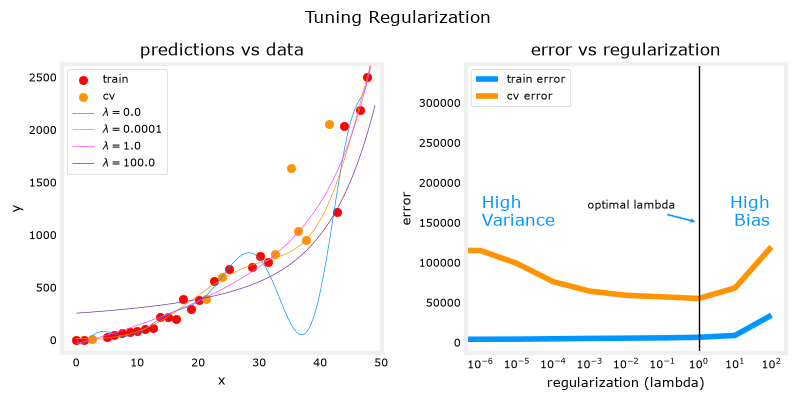

In [15]:
lambda_range = np.array([0.0, 1e-6, 1e-5, 1e-4,1e-3,1e-2, 1e-1,1,10,100])
num_steps = len(lambda_range)
degree = 10
err_train = np.zeros(num_steps)    
err_cv = np.zeros(num_steps)       
x = np.linspace(0,int(X.max()),100) 
y_pred = np.zeros((100,num_steps))  # 每列对应一条待绘制的曲线

for i in range(num_steps):
    lambda_= lambda_range[i]
    lmodel = lin_model(degree, regularization=True, lambda_=lambda_)
    lmodel.fit(X_train, y_train)
    yhat = lmodel.predict(X_train)
    err_train[i] = lmodel.mse(y_train, yhat)
    yhat = lmodel.predict(X_cv)
    err_cv[i] = lmodel.mse(y_cv, yhat)
    y_pred[:,i] = lmodel.predict(x)
    
optimal_reg_idx = np.argmin(err_cv) 

plt.close("all")
plt_tune_regularization(X_train, y_train, X_cv, y_cv, x, y_pred, err_train, err_cv, optimal_reg_idx, lambda_range)

## 评估学习算法(神经网络)

首先创建一个分类数据集

X_train.shape: (400, 2) X_cv.shape: (320, 2) X_test.shape: (80, 2)


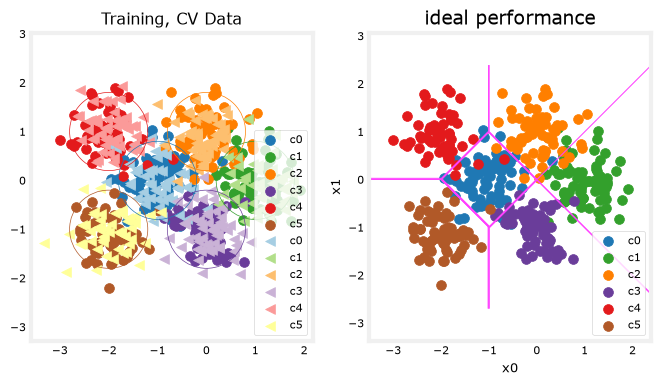

In [17]:
# 生成并划分数据集
X, y, centers, classes, std = gen_blobs()

# 划分数据。为便于演示，使用较大的交叉验证集（CV）
X_train, X_, y_train, y_ = train_test_split(X, y, test_size=0.50, random_state=1)
X_cv, X_test, y_cv, y_test = train_test_split(X_, y_, test_size=0.20, random_state=1)
print('X_train.shape:', X_train.shape, 'X_cv.shape:', X_cv.shape, 'X_test.shape:', X_test.shape)

plt_train_eq_dist(X_train, y_train, classes, X_cv, y_cv, centers, std)

用于分类模型的评估函数
$$
J_{cv}=\frac{1}{m}\sum_{i=0}^{m-1}
\begin{cases}
    1, & \text{if $\hat{y}^{(i)} \neq y^{(i)}$}\\
    0, & \text{otherwise}
\end{cases}
$$

In [18]:
def eval_cat_err(y, yhat):
    """
    计算分类误差。

    参数：
        y (ndarray  Shape (m,) or (m,1)): 每个样本的目标值
        yhat (ndarray  Shape (m,) or (m,1)): 每个样本的预测值

    返回：
        cerr (scalar): 误差
    """

    m = len(y)
    cerr = 0

    for i in range(m):
        if (y[i] != yhat[i]):
            cerr += 1

    cerr /= m

    return cerr

下面构建两个模型，一个复杂模型和一个简单模型，我们来判断它们是否过拟合或欠拟合

### 复杂模型

In [19]:
# 复杂模型
import logging

logging.getLogger('tensorflow').setLevel(logging.ERROR)

tf.random.set_seed(1234)

model = Sequential(
    [
        Dense(120, activation='relu', name='L1'),
        Dense(40, activation='relu', name='L2'),
        Dense(classes, activation='linear', name='l3')
    ], name='Complex'
)
model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(0.01)
)

model.fit(
    X_train,
    y_train,
    epochs=1000
)

Epoch 1/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.2403   
Epoch 2/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4410 
Epoch 3/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3442 
Epoch 4/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3000 
Epoch 5/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2432 
Epoch 6/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2434 
Epoch 7/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2363 
Epoch 8/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2230 
Epoch 9/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2163 
Epoch 10/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2180 
Epoch 11/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2159 
Epoch 12/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2127 
Epoch 13/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2114 
Epoch 14/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2094 
Epoch 15/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 

Model: "Complex"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ L1 (Dense)                      │ (None, 120)            │           360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L2 (Dense)                      │ (None, 40)             │         4,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l3 (Dense)                      │ (None, 6)              │           246 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,340 (127.66 KB)

 Trainable params: 5,446 (42.55 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,894 (85.11 KB)

1082/1082 ━━━━━━━━━━━━━━━━━━━━ 1s 514us/step
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 1s 506us/step


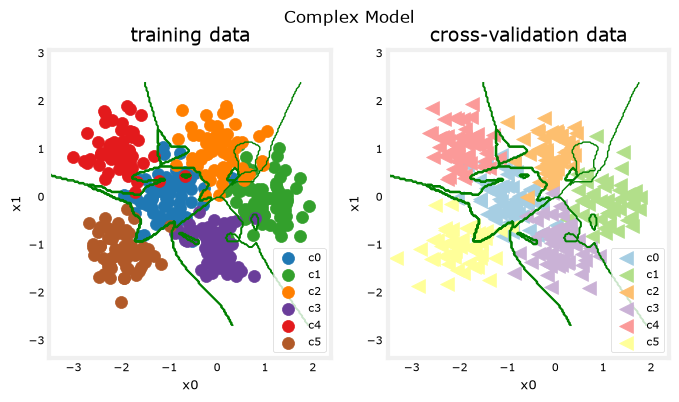

In [20]:
model.summary()

model_predict = lambda Xl: np.argmax(tf.nn.softmax(model.predict(Xl)).numpy(), axis=1)
plt_nn(model_predict, X_train, y_train, classes, X_cv, y_cv, suptitle='Complex Model')

该模型竭力拟合每个类别中的离散点，结果对部分交叉验证数据进行了错误分类，下面计算分类误差

In [21]:
training_cerr_complex = eval_cat_err(y_train, model_predict(X_train))
cv_cerr_complex = eval_cat_err(y_cv, model_predict(X_cv))
print(f'categorization error, training, complex model: {training_cerr_complex:0.3f}')
print(f'categorization error, cv,       complex model: {cv_cerr_complex:0.3f}')

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
categorization error, training, complex model: 0.005
categorization error, cv,       complex model: 0.100


### 简单模型

In [22]:
import logging

logging.getLogger('tensorflow').setLevel(logging.ERROR)

tf.random.set_seed(1234)

model_s = Sequential(
    [
        Dense(6, activation='relu', name='L1'),
        Dense(classes, activation='linear', name='L2')
    ], name='Simple'
)
model_s.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(0.01)
)

model_s.fit(
    X_train,
    y_train,
    epochs=1000
)

Epoch 1/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.9447  
Epoch 2/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.6004 
Epoch 3/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.3549 
Epoch 4/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.1140 
Epoch 5/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8807 
Epoch 6/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6891 
Epoch 7/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5607 
Epoch 8/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4831 
Epoch 9/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4340 
Epoch 10/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4002 
Epoch 11/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3751 
Epoch 12/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3553 
Epoch 13/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3390 
Epoch 14/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3250 
Epoch 15/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0

Model: "Simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ L1 (Dense)                      │ (None, 6)              │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L2 (Dense)                      │ (None, 6)              │            42 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 182 (1.42 KB)

 Trainable params: 60 (480.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 122 (976.00 B)

1082/1082 ━━━━━━━━━━━━━━━━━━━━ 1s 488us/step
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 1s 528us/step


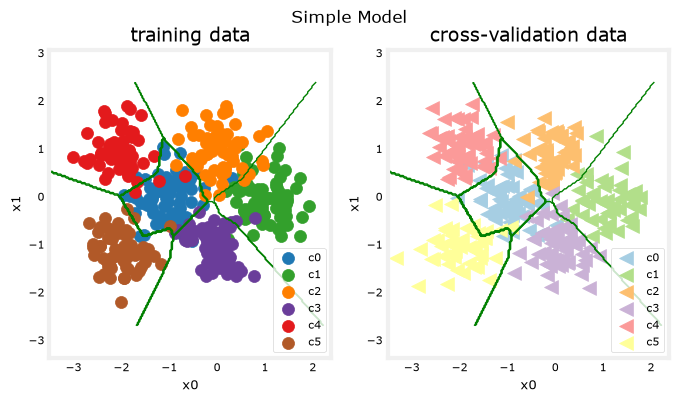

In [23]:
model_s.summary()

model_predict_s = lambda Xl: np.argmax(tf.nn.softmax(model_s.predict(Xl)).numpy(), axis=1)
plt_nn(model_predict_s, X_train, y_train, classes, X_cv, y_cv, suptitle='Simple Model')

这个简单模型看着表现不错，下面计算分类误差

In [24]:
training_cerr_simple = eval_cat_err(y_train, model_predict_s(X_train))
cv_cerr_simple = eval_cat_err(y_cv, model_predict_s(X_cv))
print(f'categorization error, training, simple model, {training_cerr_simple:0.3f}, complex model: {training_cerr_complex:0.3f}')
print(f'categorization error, cv,       simple model, {cv_cerr_simple:0.3f}, complex model: {cv_cerr_complex:0.3f}')

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
categorization error, training, simple model, 0.070, complex model: 0.005
categorization error, cv,       simple model, 0.069, complex model: 0.100



简单模型在训练数据上的分类误差略高，但在交叉验证数据上的表现优于复杂模型

## 正则化

与多项式回归一样，我们可以通过正则化参数来缓解模型过于复杂带来的影响

In [25]:
tf.random.set_seed(1234)

model_r = Sequential(
    [
        Dense(120, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.1), name='L1'), # 加入L2正则化
        Dense(40, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.1), name='L2'),
        Dense(classes, activation='linear', name='L3')
    ], name='ComplexRegularized'
)

model_r.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(0.01)
)

model_r.fit(
    X_train,
    y_train,
    epochs=1000
)

Epoch 1/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 4.4316  
Epoch 2/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.6303 
Epoch 3/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.3003 
Epoch 4/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0886 
Epoch 5/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0001 
Epoch 6/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9508 
Epoch 7/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9093 
Epoch 8/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8683 
Epoch 9/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8329 
Epoch 10/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8129 
Epoch 11/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7971 
Epoch 12/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7786 
Epoch 13/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7584 
Epoch 14/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7409 
Epoch 15/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0

Model: "ComplexRegularized"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ L1 (Dense)                      │ (None, 120)            │           360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L2 (Dense)                      │ (None, 40)             │         4,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L3 (Dense)                      │ (None, 6)              │           246 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,340 (127.66 KB)

 Trainable params: 5,446 (42.55 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,894 (85.11 KB)

1082/1082 ━━━━━━━━━━━━━━━━━━━━ 1s 504us/step
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 1s 571us/step


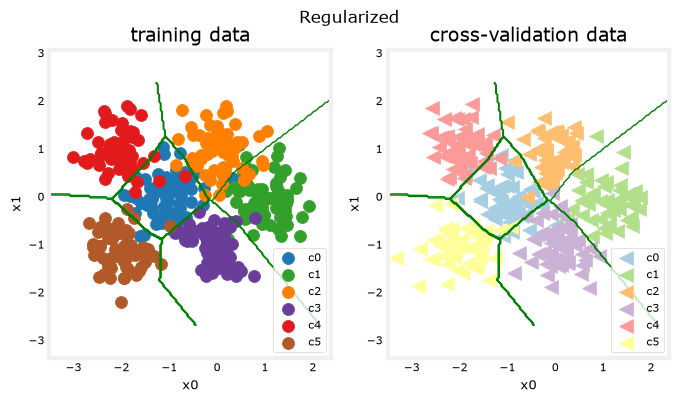

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
categorization error, training, regularized: 0.072, simple model, 0.070, complex model: 0.005
categorization error, cv,       regularized: 0.066, simple model, 0.069, complex model: 0.100


In [26]:

model_r.summary()

model_predict_r = lambda Xl: np.argmax(tf.nn.softmax(model_r.predict(Xl)).numpy(), axis=1)
plt_nn(model_predict_r, X_train, y_train, classes, X_cv, y_cv, suptitle='Regularized')

# 分类误差
training_cerr_reg = eval_cat_err(y_train, model_predict_r(X_train))
cv_cerr_reg = eval_cat_err(y_cv, model_predict_r(X_cv))
test_cerr_reg = eval_cat_err(y_test, model_predict_r(X_test))
print(f'categorization error, training, regularized: {training_cerr_reg:0.3f}, simple model, {training_cerr_simple:0.3f}, complex model: {training_cerr_complex:0.3f}')
print(f'categorization error, cv,       regularized: {cv_cerr_reg:0.3f}, simple model, {cv_cerr_simple:0.3f}, complex model: {cv_cerr_complex:0.3f}')